# Práctica 5 - Análisis Exploratorio de Datos (EDA)

**Sesión 5 - Exploración de datos**    
**Herramientas:** Python, pandas y Matplotlib  
**Dataset:** `clientes_ecommerce.csv`

## Objetivos

En esta práctica aprenderás a:

- realizar un análisis exploratorio de un dataset
- estudiar distribuciones numéricas y categóricas
- interpretar media, mediana, cuartiles y desviación estándar
- utilizar histogramas, gráficos de barras, boxplots y diagramas de dispersión
- detectar posibles valores atípicos mediante el IQR
- estudiar relaciones entre variables
- calcular e interpretar correlaciones
- comparar grupos mediante `groupby()` y `crosstab()`
- diferenciar asociación y causalidad
- comunicar hallazgos respaldados por evidencia

> **Importante:** no basta con generar resultados o gráficos. Cada análisis debe ir acompañado de una **interpretación**

## Preparación

Coloca `clientes_ecommerce.csv` en la misma carpeta que este notebook.

Importa NumPy, pandas y Matplotlib y carga el dataset en un DataFrame llamado `df`

In [1]:
# TODO: importa numpy, pandas y matplotlib.pyplot
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# TODO: carga clientes_ecommerce.csv en un DataFrame llamado df
df = pd.read_csv('clientes_ecommerce.csv')

# Parte 1 - Inspección inicial

## Ejercicio 1

Realiza una inspección inicial:

1. Muestra las primeras 10 filas.
2. Consulta las dimensiones.
3. Muestra los nombres de las columnas.
4. Consulta los tipos de datos.
5. Utiliza `info()`.

In [2]:
# TODO: muestra las primeras 10 filas
df.head(10)

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
0,20001,67,102.0,9000.00,60.73,7,3,Móvil,Oeste,Oro,5,No
1,20002,28,93.0,35683.86,131.74,6,1,Móvil,Este,Bronce,2,No
2,20003,19,87.0,37152.19,55.33,8,1,Ordenador,Este,Plata,5,Sí
3,20004,55,79.0,40158.29,24.33,7,0,Ordenador,Norte,Bronce,4,Sí
4,20005,39,3.0,27317.06,88.78,5,0,Móvil,Sur,Bronce,4,No
5,20006,45,25.0,32627.01,59.77,9,2,Móvil,Este,Bronce,5,No
6,20007,22,105.0,44101.68,109.67,8,0,Móvil,Norte,Oro,5,Sí
7,20008,39,90.0,44882.10,57.56,7,2,Ordenador,Norte,Plata,2,Sí
8,20009,55,56.0,55299.19,49.94,6,2,Móvil,Sur,Bronce,5,No
9,20010,38,93.0,9000.00,110.69,10,2,Ordenador,Centro,Oro,4,Sí


In [3]:
# TODO: consulta las dimensiones
df.shape

(400, 12)

In [4]:
# TODO: muestra los nombres de las columnas
for c in df.columns:
    print(c)

cliente_id
edad
antiguedad_meses
ingresos_anuales
gasto_mensual
num_compras
devoluciones
dispositivo
zona
nivel_fidelidad
satisfaccion
compra_proximo_mes


In [5]:
# TODO: consulta los tipos de datos
print(df.dtypes)

for i, t in df.dtypes.items():
    print(f"columna: {i}, nombre: {t}")

print(df.dtypes.values)

cliente_id              int64
edad                    int64
antiguedad_meses      float64
ingresos_anuales      float64
gasto_mensual         float64
num_compras             int64
devoluciones            int64
dispositivo               str
zona                      str
nivel_fidelidad           str
satisfaccion            int64
compra_proximo_mes        str
dtype: object
columna: cliente_id, nombre: int64
columna: edad, nombre: int64
columna: antiguedad_meses, nombre: float64
columna: ingresos_anuales, nombre: float64
columna: gasto_mensual, nombre: float64
columna: num_compras, nombre: int64
columna: devoluciones, nombre: int64
columna: dispositivo, nombre: str
columna: zona, nombre: str
columna: nivel_fidelidad, nombre: str
columna: satisfaccion, nombre: int64
columna: compra_proximo_mes, nombre: str
[dtype('int64') dtype('int64') dtype('float64') dtype('float64')
 dtype('float64') dtype('int64') dtype('int64')
 <StringDtype(storage='python', na_value=nan)>
 <StringDtype(storage='pyt

In [6]:
# TODO: utiliza info()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cliente_id          400 non-null    int64  
 1   edad                400 non-null    int64  
 2   antiguedad_meses    395 non-null    float64
 3   ingresos_anuales    396 non-null    float64
 4   gasto_mensual       397 non-null    float64
 5   num_compras         400 non-null    int64  
 6   devoluciones        400 non-null    int64  
 7   dispositivo         400 non-null    str    
 8   zona                400 non-null    str    
 9   nivel_fidelidad     400 non-null    str    
 10  satisfaccion        400 non-null    int64  
 11  compra_proximo_mes  400 non-null    str    
dtypes: float64(3), int64(5), str(4)
memory usage: 37.6 KB


### Responde

1. ¿Cuántas muestras contiene?
2. ¿Cuántas columnas?
3. ¿Cuál es la unidad de observación?
4. ¿Cuál es el identificador?
5. ¿Cuál es el target?
6. ¿Qué columnas tienen valores ausentes?

**Respuesta:**  
1. Tiene 400 muestras
2. Tiene 12 columnas
3. Es cliente.
4. Es cliente_id
5. Es compra_proximo_mes
6. antiguedad_meses (tiene 395, faltan 5)
   ingresos_anuales (tiene 396, faltan 4)
   gasto_mensual (tiene 397, faltan 3)

# Parte 2 - Exploración de una variable numérica

Vamos a estudiar `gasto_mensual`.

## Ejercicio 2 - Estadística descriptiva

Obtén el número de valores, media, mediana, desviación estándar, mínimo, \(Q_1\), \(Q_2\), \(Q_3\) y máximo.

In [7]:
# TODO: muestra describe() para gasto_mensual
print(df["gasto_mensual"].describe())

# TODO: calcula las medidas necesarias
print(df["gasto_mensual"].median())
print("Q1: ", df["gasto_mensual"].quantile(.25))
print("Q2: ", df["gasto_mensual"].quantile(.5))
print("Q3: ", df["gasto_mensual"].quantile(.75))


count    397.000000
mean      69.089320
std       39.023238
min        5.770000
25%       39.720000
50%       61.170000
75%       90.150000
max      260.000000
Name: gasto_mensual, dtype: float64
61.17
Q1:  39.72
Q2:  61.17
Q3:  90.15


### Completa

| Medida | Valor |
|---|---:|
| Número de valores | 397 |
| Media | 69.089320 |
| Mediana | 61.17 |
| Desviación estándar | 39.023238 |
| Mínimo | 5.77 |
| Q1 | 39.72 |
| Q2 | 61.17 |
| Q3 | 90.15 |
| Máximo | 260 |

### Interpreta

1. ¿Coinciden exactamente media y mediana?
2. ¿Cuál es mayor?
3. ¿Qué puede indicar esta diferencia sobre la distribución?
4. ¿Entre qué valores se encuentra aproximadamente el 50 % central?

**Respuesta:**  
1. No
2. La media
3. Hay un sesgo positivo, hacia la derecha.
4. Q1 (25%): 39.72
   Q3 (75%): 90.15

# Parte 3 - Visualizar la distribución

## Ejercicio 3 - Histograma

Crea un histograma de `gasto_mensual` utilizando aproximadamente `bins=15`.

Añade título y etiquetas en ambos ejes.

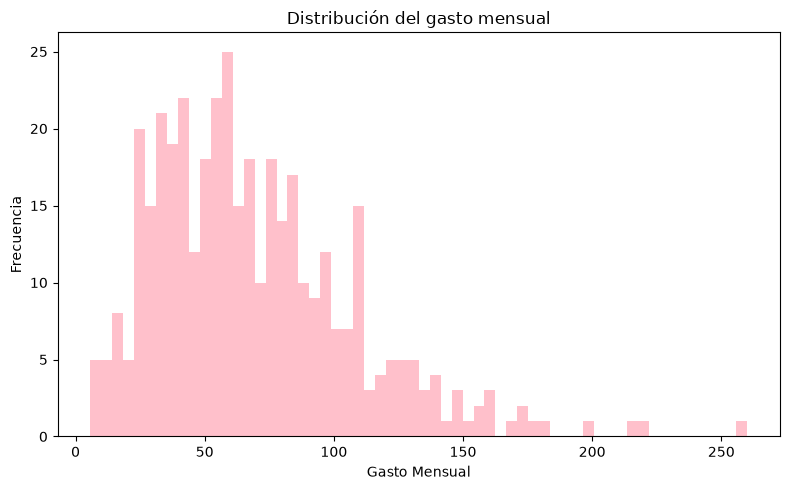

In [8]:
# TODO: crea el histograma de gasto_mensual
plt.figure(figsize = (8,5))
plt.hist(df["gasto_mensual"].dropna(), bins = 60, color = "pink")
plt.xlabel("Gasto Mensual")
plt.ylabel("Frecuencia")
plt.title("Distribución del gasto mensual")
plt.tight_layout()
plt.show()

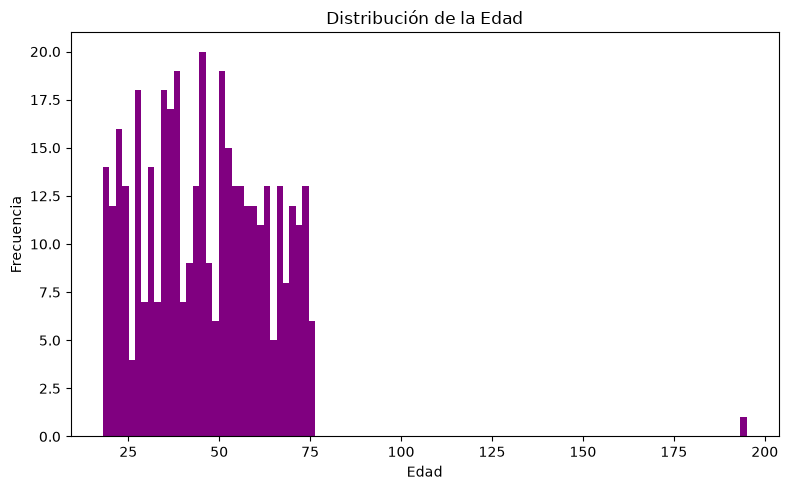

In [9]:
# TODO: crea el histograma de gasto_mensual
plt.figure(figsize = (8,5))
plt.hist(df["edad"].dropna(), bins = 100, color = "purple")
plt.xlabel("Edad")
plt.ylabel("Frecuencia")
plt.title("Distribución de la Edad")
plt.tight_layout()
plt.show() #ALGUIEN CON 200 AÑOS WOW :0

### Interpreta

1. ¿Dónde parece concentrarse la mayoría de los clientes?
2. ¿La distribución parece aproximadamente simétrica?
3. ¿Existe una cola hacia valores altos o bajos?
4. ¿Observas valores alejados del resto?

**Respuesta:**  
1. Entre 25 a 110 unidades.
2. No.
3. Hacia los valores altos a la derecha.
4. Sí

# Parte 4 - Boxplot y valores atípicos

## Ejercicio 4

Representa `gasto_mensual` mediante un boxplot. Trata adecuadamente los valores ausentes.

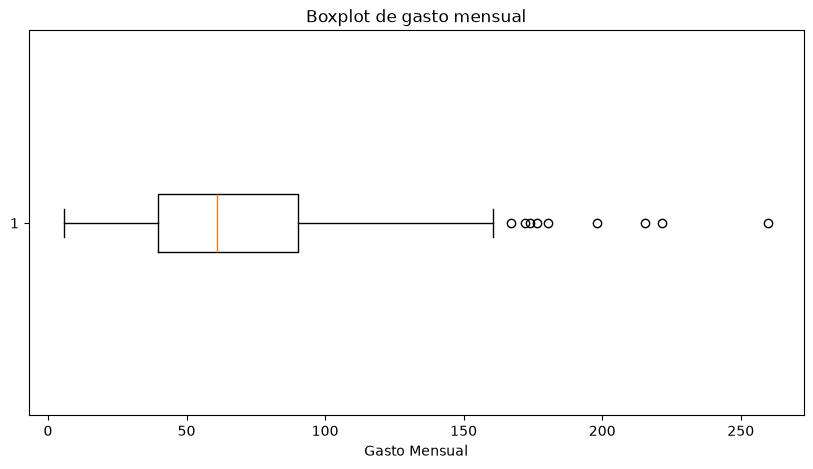

In [10]:
# TODO: crea un boxplot de gasto_mensual
plt.figure(figsize = (10, 5))
plt.boxplot(df["gasto_mensual"].dropna(), orientation = "horizontal") #Linea de la derecha es el valor maximo que no se considera atípico, después
plt.xlabel("Gasto Mensual")                                           #de esa línea los valores se consideran atípicos
plt.title("Boxplot de gasto mensual")                                
plt.show()

#El primer cuantil son los valores que están por debajo del 25%. El segundo del 50% esta por debajo del valor. El tercero del 75% esta por debajo del valor.
#El cuantil uno es la primera linea del rectangulo, el cuantil dos es la línea amarilla, y el tercero es la tercera linea del rectangulo.
#El IQR es el rectangulo


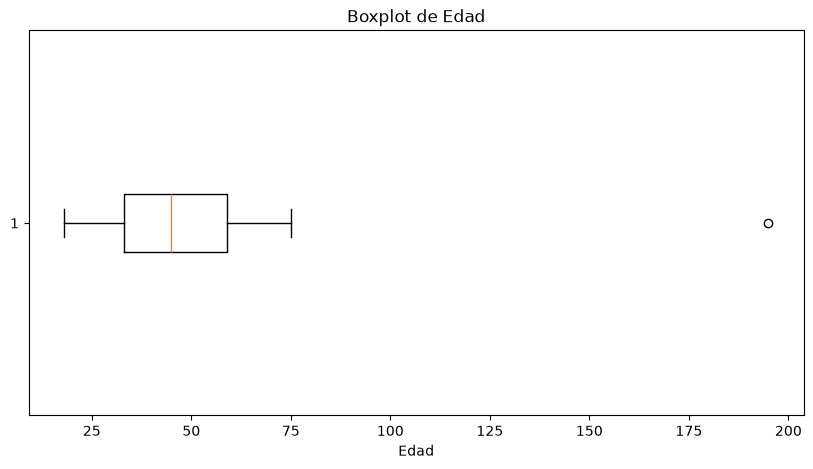

In [11]:
# TODO: crea un boxplot de gasto_mensual
plt.figure(figsize = (10, 5))
plt.boxplot(df["edad"].dropna(), orientation = "horizontal") #Linea de la derecha es el valor maximo que no se considera atípico, después
plt.xlabel("Edad")                                           #de esa línea los valores se consideran atípicos
plt.title("Boxplot de Edad")                                
plt.show()

#El primer cuantil son los valores que están por debajo del 25%. El segundo del 50% esta por debajo del valor. El tercero del 75% esta por debajo del valor.
#El cuantil uno es la primera linea del rectangulo, el cuantil dos es la línea amarilla, y el tercero es la tercera linea del rectangulo.
#El IQR es el rectangulo


### Interpreta

1. ¿Dónde se encuentra aproximadamente la mediana?
2. ¿Observas posibles outliers?
3. ¿Aparecen principalmente por encima o por debajo?
4. ¿Podemos afirmar que esos valores son errores únicamente observando el boxplot? Justifica.

**Respuesta:**  
1. En 61.
2. Sí, entre 165 y 180, otros dos de 200 y 220, y uno más en 260.
3. Solo por arriba.
4. No. El gráfico solo muestra que son valores matemáticamente inusuales. Para confirmar un error, se debe auditar la fuente de datos, no el gráfico.

# Parte 5 - Detectar outliers mediante IQR

## Ejercicio 5

Calcula:

$$
IQR=Q_3-Q_1
$$

y:

$$
L_{inferior}=Q_1-1.5IQR
$$

$$
L_{superior}=Q_3+1.5IQR
$$

Después localiza los clientes cuyo `gasto_mensual` esté fuera de estos límites y guarda el resultado en `outliers_gasto`.

In [12]:
# TODO: calcula Q1, Q3 e IQR
Q1 = df["gasto_mensual"].quantile(.25)
#Q2 = df["gasto_mensual"].quantile(.5)
Q3 = df["gasto_mensual"].quantile(.75)

IQR = Q3 - Q1 #Rango Intercutilico

# TODO: calcula los límites inferior y superior
l_Inferior = Q1 - 1.5*IQR
l_Superior = Q3 + 1.5*IQR

# TODO: muestra los resultados
print(f"IQR: {IQR:.2f}, LInferior: {l_Inferior:.2f}, LSuperior: {l_Superior:.2f}")

IQR: 50.43, LInferior: -35.93, LSuperior: 165.80


In [13]:
# TODO: calcula Q1, Q3 e IQR
Q1_Edad = df["edad"].quantile(.25)
#Q2_Edad = df["edad"].quantile(.5)
Q3_Edad = df["edad"].quantile(.75)

IQR_Edad = Q3_Edad - Q1_Edad #Rango Intercutilico

# TODO: calcula los límites inferior y superior
l_Inferior_Edad = Q1_Edad - 1.5*IQR_Edad
l_Superior_Edad = Q3_Edad + 1.5*IQR_Edad

# TODO: muestra los resultados
print(f"IQR: {IQR_Edad:.2f}, LInferior: {l_Inferior_Edad:.2f}, LSuperior: {l_Superior_Edad:.2f}")

IQR: 26.00, LInferior: -6.00, LSuperior: 98.00


In [14]:
# TODO: crea outliers_gasto
filtro = (df["gasto_mensual"]<l_Inferior) | (df["gasto_mensual"]>l_Superior)
outliers = df[filtro]

# TODO: muestra los posibles outliers
outliers

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
50,20051,75,49.0,22908.36,176.52,3,1,Móvil,Este,Oro,3,Sí
68,20069,29,78.0,33382.86,215.30,8,2,Móvil,Centro,Bronce,4,No
202,20203,45,57.0,24727.71,167.26,7,4,Móvil,Norte,Platino,1,Sí
203,20204,25,41.0,39329.38,173.91,6,0,Ordenador,Norte,Bronce,2,Sí
207,20208,41,65.0,25812.18,221.59,10,0,Ordenador,Centro,Plata,5,Sí
268,20269,21,61.0,34737.20,198.28,7,2,Tablet,Centro,Bronce,3,Sí
292,20293,20,94.0,31714.55,172.31,13,0,Tablet,Este,Bronce,3,Sí
318,20319,56,38.0,9000.00,180.60,4,0,Ordenador,Este,Bronce,2,Sí
398,20399,75,85.0,40391.73,260.00,10,1,Móvil,Oeste,Bronce,4,Sí


In [15]:
# TODO: crea outliers_gasto
filtroEdad = (df["edad"]<l_Inferior_Edad) | (df["edad"]>l_Superior_Edad)
outliersEdad = df[filtroEdad]

# TODO: muestra los posibles outliers
outliersEdad

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
137,20138,195,106.0,32593.41,138.99,6,0,Móvil,Este,Plata,3,No


### Responde

1. ¿Cuántos posibles outliers has encontrado?
2. ¿Qué porcentaje representan?
3. ¿Cuál es el mayor `gasto_mensual`?
4. ¿Eliminarías automáticamente estas observaciones?
5. ¿Qué investigarías antes?

**Respuesta:**  
1. 9 posibles outliers.
2. 2.27%
3. 260
4. No
5. Los errores del origen y el perfil del cliente.

# Parte 6 - Comparar varias distribuciones

## Ejercicio 6

Analiza:

- `edad`
- `ingresos_anuales`
- `gasto_mensual`
- `num_compras`
- `devoluciones`

Consulta sus estadísticas descriptivas y crea un histograma independiente para cada variable.

In [16]:
# TODO: consulta las estadísticas descriptivas de las variables indicadas
print(df[["edad", "ingresos_anuales", "gasto_mensual", "num_compras", "devoluciones"]].describe())

             edad  ingresos_anuales  gasto_mensual  num_compras  devoluciones
count  400.000000        396.000000     397.000000   400.000000    400.000000
mean    46.402500      36440.920379      69.089320     8.225000      1.225000
std     18.007809      14325.228166      39.023238     2.780955      1.136929
min     18.000000       9000.000000       5.770000     2.000000      0.000000
25%     33.000000      26034.092500      39.720000     6.000000      0.000000
50%     45.000000      36817.275000      61.170000     8.000000      1.000000
75%     59.000000      45969.032500      90.150000    10.000000      2.000000
max    195.000000      82925.370000     260.000000    17.000000      5.000000


In [35]:
# TODO: calcula sus medianas
print(df[["edad", "ingresos_anuales", "gasto_mensual", "num_compras", "devoluciones"]].median())

edad                   45.000
ingresos_anuales    36817.275
gasto_mensual          61.170
num_compras             8.000
devoluciones            1.000
dtype: float64


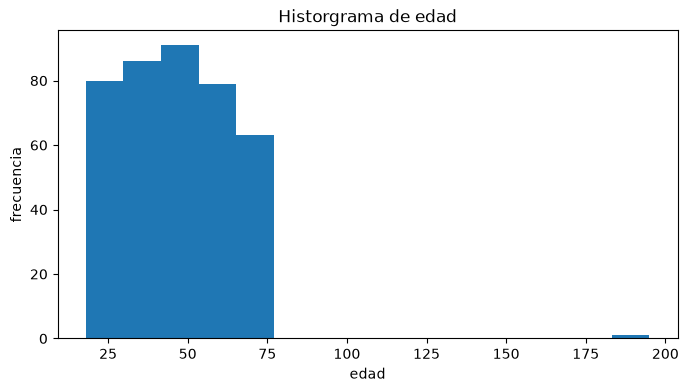

In [36]:
# TODO: histograma de edad
plt.figure(figsize=(8,4))
plt.hist(df["edad"].dropna(), bins=15)
plt.xlabel("edad")
plt.ylabel("frecuencia")
plt.title("Historgrama de edad")
plt.show()

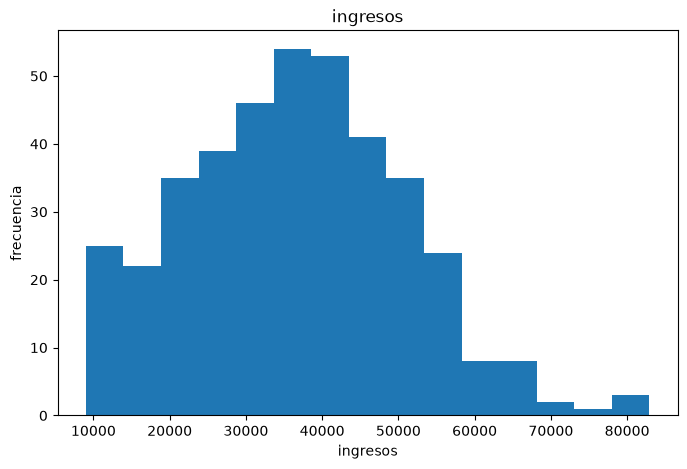

In [37]:
# TODO: histograma de ingresos_anuales
plt.figure(figsize=(8,5))
plt.hist(df["ingresos_anuales"].dropna(), bins=15)
plt.xlabel("ingresos")
plt.ylabel("frecuencia")
plt.title("ingresos")
plt.show()

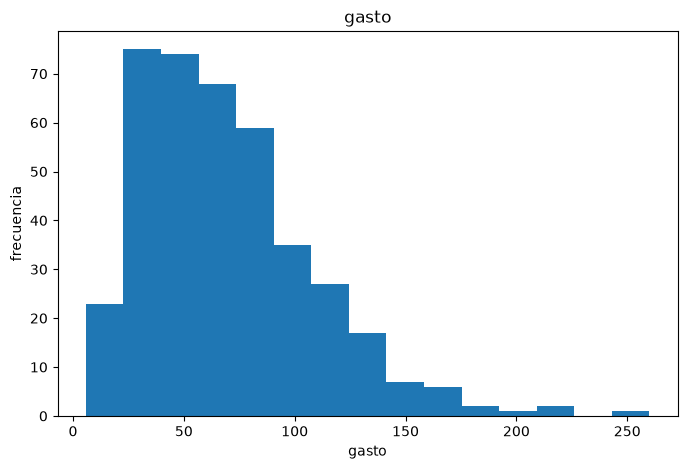

In [38]:
# TODO: histograma de gasto_mensual
plt.figure(figsize=(8,5))
plt.hist(df["gasto_mensual"].dropna(), bins=15)
plt.xlabel("gasto")
plt.ylabel("frecuencia")
plt.title("gasto")
plt.show()

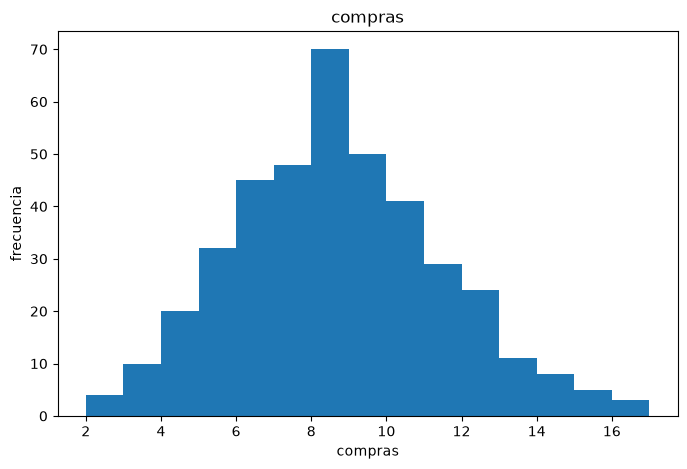

In [39]:
# TODO: histograma de num_compras
plt.figure(figsize=(8,5))
plt.hist(df["num_compras"].dropna(), bins=15)
plt.xlabel("compras")
plt.ylabel("frecuencia")
plt.title("compras")
plt.show()

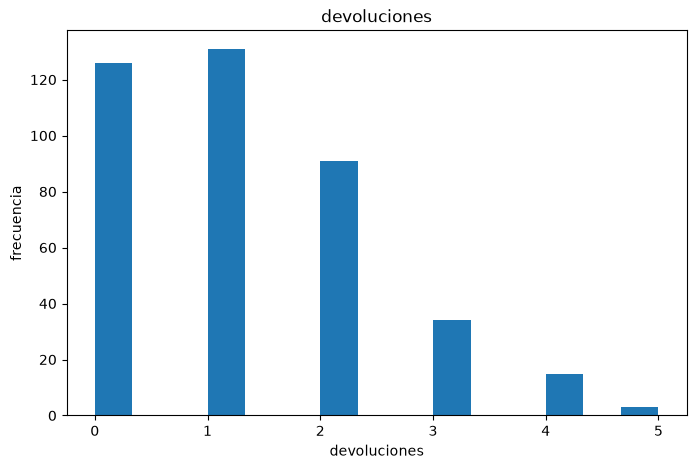

In [40]:
# TODO: histograma de devoluciones
plt.figure(figsize=(8,5))
plt.hist(df["devoluciones"].dropna(), bins=15)
plt.xlabel("devoluciones")
plt.ylabel("frecuencia")
plt.title("devoluciones")
plt.show()

### Completa

### Completa

| Variable | Media | Mediana | Mínimo | Máximo | Observación relevante |
|---|---:|---:|---:|---:|---|
| edad | 46.40 | 45.00 | 18 | 195 | Máximo de 195 años: imposible, muy alejado del resto |
| ingresos_anuales | 36440.92 | 36817.28 | 9000.00 | 82925.37 | 4 nulos, 16 clientes con exactamente 9000, parece un valor mínimo impuesto. |
| gasto_mensual | 69.09 | 61.17 | 5.77 | 260.00 | 3 nulos, asimetría a la derecha (media > mediana) y 9 outliers por arriba. |
| num_compras | 8.23 | 8.00 | 2 | 17 | Distribución bastante simétrica (media = mediana) |
| devoluciones | 1.23 | 1.00 | 0 | 5 | Valores bajos y discretos, muchos clientes con 0 devoluciones. |

### Busca una observación sospechosa

- ¿Qué variable es? edad.
- ¿Qué valor tiene? 195 años.
- ¿Por qué parece sospechoso? Porque está muy alejado del resto.
- ¿Es un outlier? Si.
- ¿Podemos afirmar directamente que es un error? Aunque sea muy raro que alguien tenga 195 años primero se tendría que justificar con datos.
- ¿Qué harías antes de modificarlo? Revisar el resto de datos para justificar.


# Parte 7 - Variables categóricas

## Ejercicio 7 - Frecuencias

Analiza `dispositivo`, `zona`, `nivel_fidelidad` y `compra_proximo_mes`.

Calcula frecuencias absolutas, relativas y porcentajes mediante `value_counts()`.

In [23]:
# TODO: analiza dispositivo
print(df["dispositivo"].value_counts())
print(df["dispositivo"].value_counts(normalize = True))
print(df["dispositivo"].value_counts(normalize = True)*100)

dispositivo
Móvil        242
Ordenador    133
Tablet        25
Name: count, dtype: int64
dispositivo
Móvil        0.6050
Ordenador    0.3325
Tablet       0.0625
Name: proportion, dtype: float64
dispositivo
Móvil        60.50
Ordenador    33.25
Tablet        6.25
Name: proportion, dtype: float64


In [24]:
# TODO: analiza zona
print(df["zona"].value_counts())
print(df["zona"].value_counts(normalize = True))
print(df["zona"].value_counts(normalize = True)*100)

zona
Este      89
Sur       80
Norte     79
Oeste     76
Centro    76
Name: count, dtype: int64
zona
Este      0.2225
Sur       0.2000
Norte     0.1975
Oeste     0.1900
Centro    0.1900
Name: proportion, dtype: float64
zona
Este      22.25
Sur       20.00
Norte     19.75
Oeste     19.00
Centro    19.00
Name: proportion, dtype: float64


In [25]:
# TODO: analiza nivel_fidelidad
print(df["nivel_fidelidad"].value_counts())
print(df["nivel_fidelidad"].value_counts(normalize = True))
print(df["nivel_fidelidad"].value_counts(normalize = True)*100)

nivel_fidelidad
Bronce     162
Plata      105
Oro         83
Platino     50
Name: count, dtype: int64
nivel_fidelidad
Bronce     0.4050
Plata      0.2625
Oro        0.2075
Platino    0.1250
Name: proportion, dtype: float64
nivel_fidelidad
Bronce     40.50
Plata      26.25
Oro        20.75
Platino    12.50
Name: proportion, dtype: float64


In [26]:
# TODO: analiza compra_proximo_mes
print(df["compra_proximo_mes"].value_counts())
print(df["compra_proximo_mes"].value_counts(normalize = True))
print(df["compra_proximo_mes"].value_counts(normalize = True)*100)

compra_proximo_mes
No    246
Sí    154
Name: count, dtype: int64
compra_proximo_mes
No    0.615
Sí    0.385
Name: proportion, dtype: float64
compra_proximo_mes
No    61.5
Sí    38.5
Name: proportion, dtype: float64


### Completa

| Variable | Categoría más frecuente | Nº muestras | Porcentaje |
|---|---|---:|---:|
| dispositivo | Móvil | 242 | 60.50 % |
| zona | Este | 89 | 22.25 % |
| nivel_fidelidad | Bronce | 162 | 40.50 % |
| compra_proximo_mes | No | 246 | 61.50 % |

# Parte 8 - Visualización de variables categóricas

## Ejercicio 8

Crea gráficos de barras independientes para:

- `dispositivo`
- `nivel_fidelidad`
- `compra_proximo_mes`

Todos deben incluir título y etiquetas.

Index(['Móvil', 'Ordenador', 'Tablet'], dtype='str', name='dispositivo')


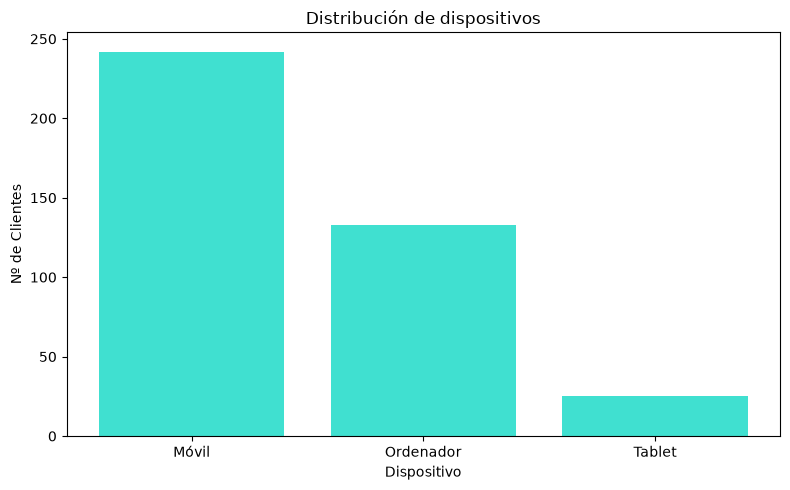

In [27]:
# TODO: gráfico de barras de dispositivo
conteos = df["dispositivo"].value_counts()
print(conteos.index)

plt.figure(figsize = (8, 5))
plt.bar(conteos.index, conteos.values, color = "turquoise")
plt.xlabel("Dispositivo")
plt.ylabel("Nº de Clientes")
plt.title("Distribución de dispositivos")
plt.tight_layout()
plt.show()

Index(['Bronce', 'Plata', 'Oro', 'Platino'], dtype='str', name='nivel_fidelidad')


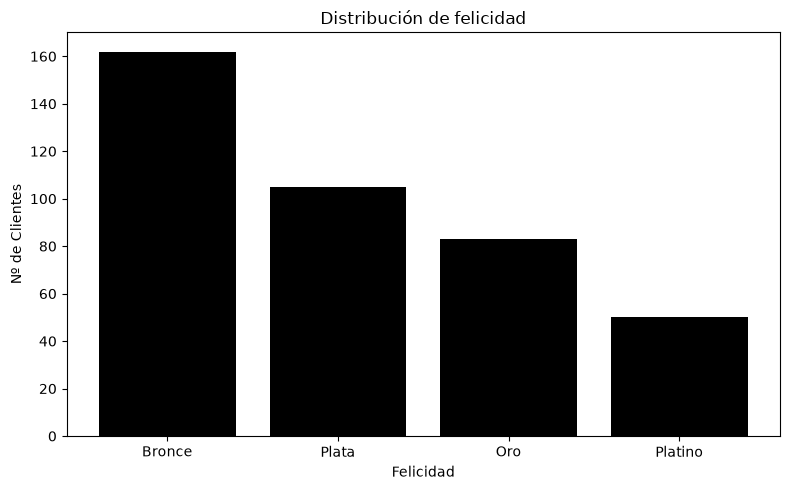

In [28]:
# TODO: gráfico de barras de nivel_fidelidad
conteosfidelidad = df["nivel_fidelidad"].value_counts()
print(conteosfidelidad.index)

plt.figure(figsize = (8, 5))
plt.bar(conteosfidelidad.index, conteosfidelidad.values, color = "black")
plt.xlabel("Felicidad")
plt.ylabel("Nº de Clientes")
plt.title("Distribución de felicidad")
plt.tight_layout()
plt.show()

Index(['No', 'Sí'], dtype='str', name='compra_proximo_mes')


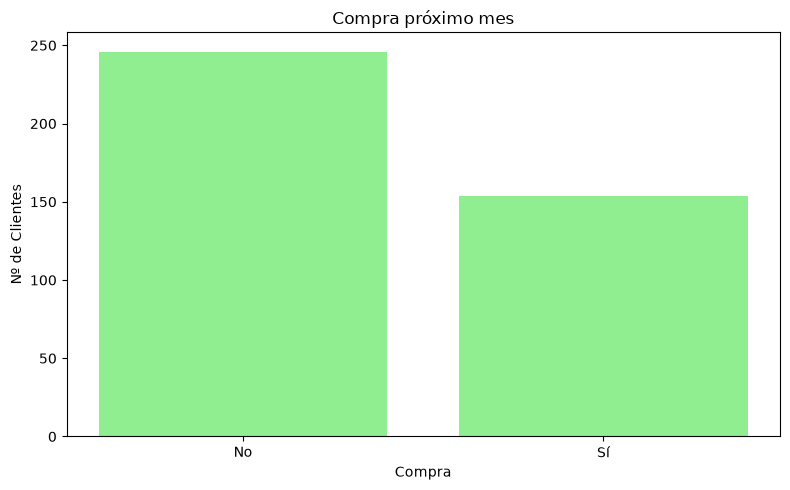

In [29]:
# TODO: gráfico de barras de compra_proximo_mes
conteoscompra_proximo_mes = df["compra_proximo_mes"].value_counts()
print(conteoscompra_proximo_mes.index)

plt.figure(figsize = (8, 5))
plt.bar(conteoscompra_proximo_mes.index, conteoscompra_proximo_mes.values, color = "Lightgreen")
plt.xlabel("Compra")
plt.ylabel("Nº de Clientes")
plt.title("Compra próximo mes")
plt.tight_layout()
plt.show()

### Interpreta

Escribe al menos una conclusión sobre cada gráfico.

Para `compra_proximo_mes`, responde además:

> ¿Las clases están perfectamente equilibradas?

Justifica utilizando porcentajes.

**Respuesta:**  
Escribe aquí.

# Parte 9 - Relación entre dos variables numéricas

Queremos investigar:

> **¿Existe alguna relación entre el número de compras realizadas y el gasto mensual?**

## Ejercicio 9 - Scatter plot

Representa:

$$
X=\text{num\_compras}
$$

$$
Y=\text{gasto\_mensual}
$$

mediante un diagrama de dispersión.

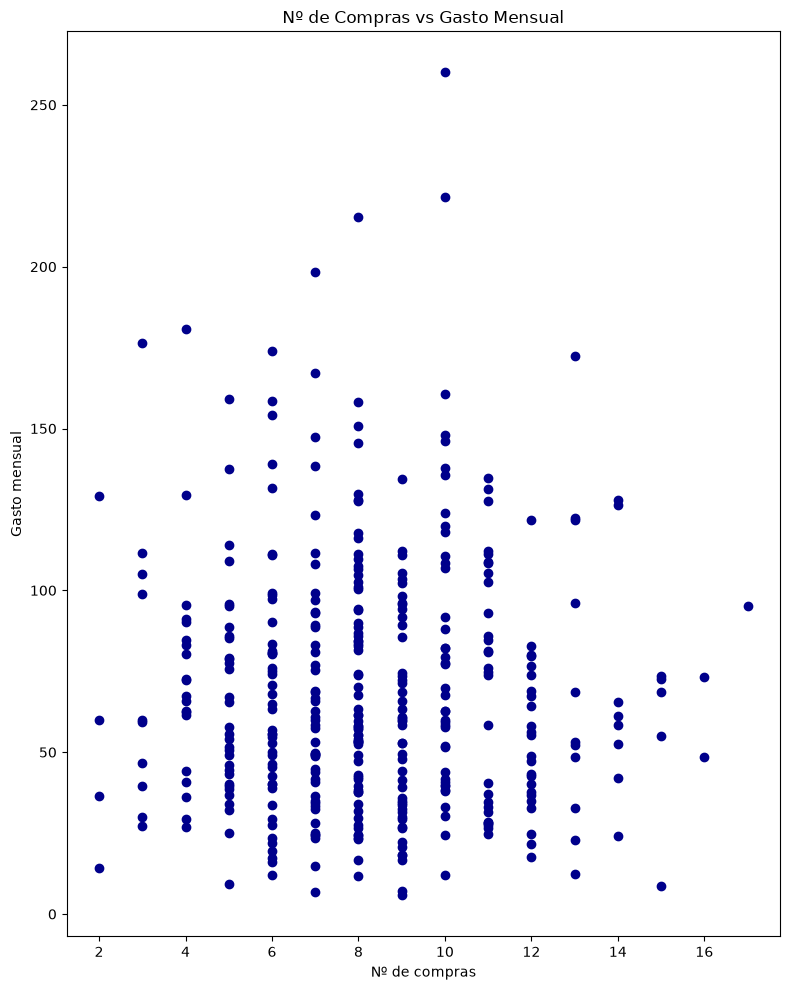

In [30]:
# TODO: crea un scatter plot de num_compras frente a gasto_mensual
plt.figure(figsize = (8, 10))
plt.scatter(df["num_compras"], df["gasto_mensual"], color = "darkblue")
plt.xlabel("Nº de compras")
plt.ylabel("Gasto mensual")
plt.title("Nº de Compras vs Gasto Mensual")
plt.tight_layout()
plt.show()

### Antes de calcular la correlación

1. ¿Parece existir una relación?
2. ¿Parece positiva o negativa?
3. ¿Parece fuerte o débil?
4. ¿Observas muestras especialmente alejadas?

**Respuesta:**  
1. No
2. Prácticamente neutra
3. Débil
4. Sí, varios outliers.

# Parte 10 - Correlación

## Ejercicio 10

Calcula la correlación entre `num_compras` y `gasto_mensual` utilizando `corr()`.

In [31]:
# TODO: calcula la correlación entre num_compras y gasto_mensual
print(df["num_compras"].corr(df["gasto_mensual"]))
#Si el dato es muy proximo a 0 no hay correlación
#Si el dato es cercano a -1 es correlación negativa.
#Si el dato es cercano a 1 es correlación positiva

-0.014165499001183262


### Interpreta

1. ¿Cuál es el valor de \(r\)?
2. ¿Es positivo o negativo?
3. ¿Qué significa el signo?
4. ¿Coincide con lo observado en el scatter plot?
5. ¿Podemos afirmar que realizar más compras **provoca** un mayor gasto mensual? Justifica.

**Respuesta:**  
1. -0.0142
2. Negativo
3. La correlación es neutra
4. Sí
5. No, en absoluto. El valor es casi cero (-0.0142), lo que demuestra que no hay relación entre las variables.

# Parte 11 - Matriz de correlaciones

## Ejercicio 11

Selecciona las variables numéricas y calcula su matriz de correlaciones.

> **Atención:** `cliente_id` es técnicamente numérico, pero conceptualmente es un identificador. No debes incluirlo.

In [41]:
# TODO: selecciona las variables numéricas excluyendo cliente_id
numericas = df.select_dtypes(include="number").drop(columns=["cliente_id"])
# TODO: calcula y muestra la matriz de correlaciones
correlaciones = numericas.corr()
correlaciones

,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,satisfaccion
edad,1.000000,0.031192,-0.036610,0.021361,-0.077583,-0.097102,-0.062801
antiguedad_meses,0.031192,1.000000,-0.058738,0.006482,-0.099965,-0.056458,-0.040051
ingresos_anuales,-0.036610,-0.058738,1.000000,-0.000367,0.072991,0.000260,-0.062595
gasto_mensual,0.021361,0.006482,-0.000367,1.000000,-0.014165,0.030674,-0.054523
num_compras,-0.077583,-0.099965,0.072991,-0.014165,1.000000,-0.005747,0.092211
devoluciones,-0.097102,-0.056458,0.000260,0.030674,-0.005747,1.000000,0.030817
satisfaccion,-0.062801,-0.040051,-0.062595,-0.054523,0.092211,0.030817,1.000000


### Interpreta

1. ¿Por qué todos los valores de la diagonal son 1? Cada variable se compara consigo misma, dando una correlación perfecta.
2. ¿Por qué la matriz es simétrica? La correlación de A con B es igual a la de B con A.
3. Sin considerar la diagonal, ¿qué pareja presenta la correlación positiva más alta? num_compras y satisfaccion (0.092).
4. ¿Qué pareja presenta la correlación más negativa? antiguedad_meses y num_compras (-0.100). 
5. ¿Hay variables cuya correlación sea prácticamente cero? Sí, casi todas; destacan ingresos_anuales con devoluciones (0.0003) y con gasto_mensual (-0.0004)

# Parte 12 - Visualizar las correlaciones

## Ejercicio 12

Representa la matriz mediante `plt.imshow()`.

Añade nombres de variables en ambos ejes, barra de color y título.

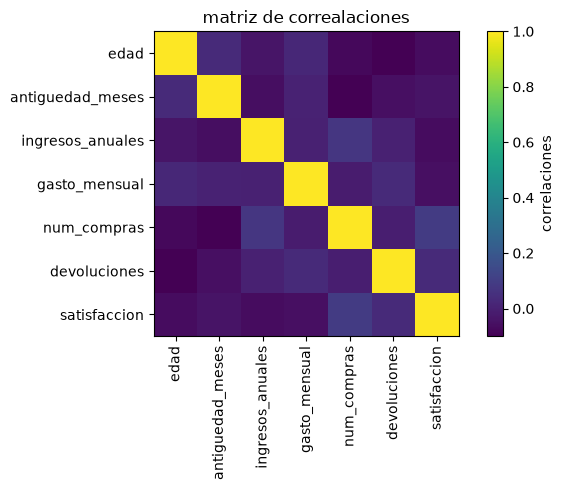

In [42]:
# TODO: representa la matriz de correlaciones con plt.imshow()
plt.figure(figsize=(7,5))
plt.imshow(correlaciones)
plt.xticks(range(len(correlaciones.columns)), correlaciones.columns, rotation=90)
plt.yticks(range(len(correlaciones.columns)), correlaciones.columns)
plt.colorbar(label="correlaciones")
plt.title("matriz de correalaciones")
plt.tight_layout()
plt.show()

### Interpreta tres relaciones

Selecciona tres relaciones de la matriz y explica qué significa cada valor.

1. **num_compras y satisfaccion (0.092):** Correlación positiva muy débil; a más compras hay una ligerísima tendencia a mayor satisfacción, pero es casi inexistente y no implica que una cosa cause la otra.
2. **antiguedad_meses y num_compras (-0.100):** Correlación negativa muy débil; los clientes más antiguos tienden levemente a comprar menos, sin que exista una relación fuerte ni causal entre ambas.
3. **ingresos_anuales y gasto_mensual (-0.0004):** Correlación prácticamente cero; no existe ninguna relación lineal entre lo que gana un cliente al año y lo que gasta al mes.

Recuerda:

$$
\boxed{\text{correlación}\neq\text{causalidad}}
$$

# Parte 13 - Variable numérica frente a categórica

Queremos investigar:

> **¿Los clientes que realizan una compra el mes siguiente presentan un gasto histórico diferente?**

## Ejercicio 13

Utiliza `groupby()` para obtener para cada valor de `compra_proximo_mes`:

- número de clientes
- gasto medio
- mediana
- desviación estándar.

In [44]:
# TODO: agrupa por compra_proximo_mes y calcula las estadísticas solicitadas
df.groupby("compra_proximo_mes")["gasto_mensual"].agg(numero_clientes="count",
                                      gasto_medio="mean", 
                                      mediana="median",
                                      desviacion_estandar="std")

,numero_clientes,gasto_medio,mediana,desviacion_estandar
compra_proximo_mes,,,,
No,245,64.589469,59.28,33.693480
Sí,152,76.342368,66.50,45.534042


In [45]:
df.groupby("compra_proximo_mes")["ingresos_anuales"].agg(numero_clientes="count",
                                                      gasto_medio="mean",
                                                      mediana="median",
                                                      desviacion_estandar="std")

,numero_clientes,gasto_medio,mediana,desviacion_estandar
compra_proximo_mes,,,,
No,245,36457.790449,36999.62,13983.264281
Sí,151,36413.548411,36715.09,14910.598296


In [46]:
df.groupby("nivel_fidelidad")["gasto_mensual"].agg(numero_clientes="count",
                                                      gasto_medio="mean",
                                                      mediana="median",
                                                      desviacion_estandar="std")

,numero_clientes,gasto_medio,mediana,desviacion_estandar
nivel_fidelidad,,,,
Bronce,159,68.201321,57.79,42.580449
Oro,83,70.932410,63.31,37.513417
Plata,105,68.686095,62.79,37.078855
Platino,50,69.700400,68.06,34.328374


### Interpreta

1. ¿Qué grupo presenta mayor gasto medio?
2. ¿Y mayor mediana?
3. ¿Las diferencias parecen grandes o pequeñas?
4. ¿La media y la mediana cuentan exactamente la misma historia?

**Respuesta:**  
Escribe aquí.

# Parte 14 - Comparación visual entre grupos

## Ejercicio 14

Crea:

- `grupo_no`: gasto mensual de quienes no compran el mes siguiente
- `grupo_si`: gasto mensual de quienes sí compran.

Representa ambos mediante un único boxplot.

Text(0, 0.5, 'gasto mensual')

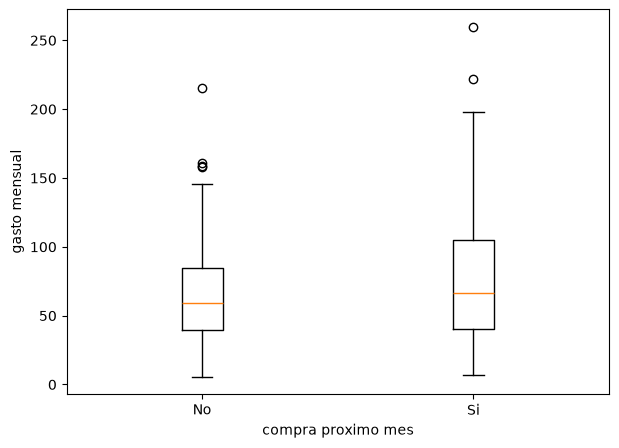

In [47]:
# TODO: crea grupo_no y grupo_si
grupo_no = df.loc[df["compra_proximo_mes"]=="No", "gasto_mensual"].dropna()
grupo_si = df.loc[df["compra_proximo_mes"]=="Sí", "gasto_mensual"].dropna()
plt.figure(figsize=(7,5))
plt.boxplot([grupo_no, grupo_si], tick_labels=["No", "Si"])
plt.xlabel("compra proximo mes")
plt.ylabel("gasto mensual")
# TODO: representa ambos grupos mediante un boxplot

### Interpreta

1. **Mediana mayor:** El grupo "Sí" presenta una mediana ligeramente superior (la línea naranja de la caja derecha está más arriba que la del grupo "No").
2. **Mayor dispersión:** El grupo "Sí" tiene mayor dispersión, ya que tanto la altura de su caja (rango intercuartílico) como la distancia entre sus bigotes son más amplias.
3. **Outliers:** Sí, ambos grupos muestran valores atípicos superiores (puntos aislados por encima del bigote máximo), aunque el grupo "Sí" alcanza valores más extremos (hasta 260).
4. **Coherencia con groupby():** Sí, el gráfico confirma visualmente lo obtenido numéricamente: quienes sí compran el próximo mes tienen un gasto mensual mediano más alto y una mayor variabilidad en sus importes, aunque con bastante solapamiento entre ambos grupos.


# Parte 15 - Dos variables categóricas

Queremos responder:

> **¿La proporción de compra es igual para todos los niveles de fidelidad?**

## Ejercicio 15

Crea:

1. una tabla de contingencia con frecuencias absolutas
2. una tabla normalizada por filas mediante `normalize="index"`
3. una versión expresada en porcentajes.

In [48]:
# TODO: tabla de contingencia con frecuencias absolutas
frecuencias = pd.crosstab(df["nivel_fidelidad"],df["compra_proximo_mes"])
frecuencias

compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,112,50
Oro,52,31
Plata,63,42
Platino,19,31


In [49]:

# TODO: tabla normalizada por filas
frecuencias = pd.crosstab(df["nivel_fidelidad"],df["compra_proximo_mes"], normalize="index")
frecuencias

compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,0.691358,0.308642
Oro,0.626506,0.373494
Plata,0.600000,0.400000
Platino,0.380000,0.620000


In [50]:
# TODO: muestra las proporciones como porcentajes
(frecuencias * 100).round(2)

compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,69.14,30.86
Oro,62.65,37.35
Plata,60.00,40.00
Platino,38.00,62.00


### Interpreta

1. **Mayor número absoluto:** Bronce, con 50 clientes que compran (Sí).
2. **Mayor porcentaje:** Platino, con un 62,00 % de clientes que compran (Sí).
3. **¿Coinciden?:** No, porque Bronce tiene muchos más clientes en total (162 frente a 50 en Platino), por lo que acumula más compras en volumen aunque su tasa de conversión sea la más baja (30,86 %).
4. **Importancia de las proporciones:** Porque permiten comparar grupos en igualdad de condiciones sin que el tamaño de cada grupo distorsione el análisis, revelando la verdadera probabilidad o tendencia de compra de cada categoría.

# Parte 16 - Correlación no implica causalidad

## Ejercicio 16 - Razonamiento

Un compañero observa una relación entre `nivel_fidelidad` y `compra_proximo_mes` y afirma:

> **«Subir a un cliente al nivel Platino hará que compre el próximo mes».**

¿Es correcta esta conclusión?

Redacta entre **5 y 8 líneas** utilizando correctamente:

- asociación
- causalidad
- variables adicionales
- evidencia

### Respuesta

No, esta conclusión es incorrecta porque confunde una simple asociación estadística con causalidad. Aunque los clientes Platino compran más (62 %), esto no demuestra que subir de nivel a un cliente provoque que compre.   

Existen variables adicionales como el gasto mensual previo, la antigüedad o el hábito de compra que explican tanto llegar a Platino como volver a comprar. Este análisis aporta evidencia de correlación, pero para probar causalidad se requeriría un experimento controlado.

# Parte 17 - Investiga una hipótesis

## Ejercicio 17

Elige **una**:

**A.** ¿Los clientes con mayores ingresos gastan más mensualmente?  
**B.** ¿Los clientes más antiguos realizan más compras?  
**C.** ¿La satisfacción está relacionada con el número de compras?  
**D.** ¿El número de devoluciones está relacionado con la satisfacción?

Realiza:

1. selección de variables
2. estadística descriptiva
3. visualización adecuada
4. correlación si procede
5. interpretación.

       ingresos_anuales  gasto_mensual
count        393.000000     393.000000
mean       36538.187277      69.024122
std        14266.841244      39.133394
min         9000.000000       5.770000
25%        26190.310000      39.670000
50%        36831.090000      61.010000
75%        45879.100000      90.150000
max        82925.370000     260.000000


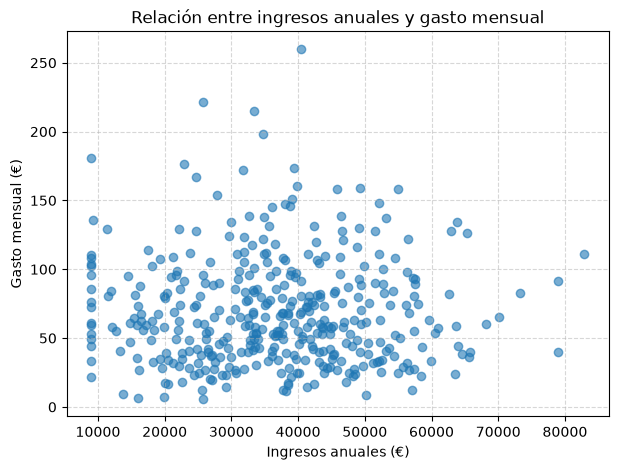

Correlaciónn: -0.000367


In [54]:
# TODO: desarrolla aquí el análisis de la hipótesis seleccionada
import matplotlib.pyplot as plt

# 1. Selección de variables (eliminando nulos para el análisis conjunto)
datos_h = df[["ingresos_anuales", "gasto_mensual"]].dropna()

# 2. Estadística descriptiva
print(datos_h.describe())

# 3. Visualización adecuada (diagrama de dispersión)
plt.figure(figsize=(7, 5))
plt.scatter(datos_h["ingresos_anuales"], datos_h["gasto_mensual"], alpha=0.6)
plt.title("Relación entre ingresos anuales y gasto mensual")
plt.xlabel("Ingresos anuales (€)")
plt.ylabel("Gasto mensual (€)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# 4. Correlación de Pearson
corr = datos_h["ingresos_anuales"].corr(datos_h["gasto_mensual"])
print(f"Correlaciónn: {corr:.6f}")

### Conclusión de la hipótesis

Redacta entre **5 y 10 líneas**. No escribas únicamente el valor de correlación.

### Hipótesis elegida: A. ¿Los clientes con mayores ingresos gastan más mensualmente?

1. **Selección de variables:** Se seleccionan ingresos_anuales (variable explicativa, numérica continua) y gasto_mensual variable respuesta, numérica continua), descartando los registros con valores nulos en ambas columnas (4 en ingresos y 3 en gasto).
2. **Estadística descriptiva:** 
   - ingresos_anuales: media de 36.440,92 € y mediana de 36.817,28 € (rango de 9.000,00 € a 82.925,37 €), distribución bastante simétrica.
   - gasto_mensual: media de 69,09 € y mediana de 61,17 € (rango de 5,77 € a 260,00 €), con asimetría a la derecha por valores altos.
3. **Visualización adecuada:** Al ser dos variables numéricas continuas, se emplea un diagrama de dispersión (scatter plot), donde se observa una nube de puntos dispersa sin ninguna tendencia ascendente ni descendente clara.
4. **Correlación:** El coeficiente de correlación de Pearson entre ambas variables es -0.000367.
5. **Interpretación:** Se rechaza la hipótesis. El coeficiente prácticamente igual a cero y la dispersión del gráfico demuestran que no existe relación lineal entre los ingresos anuales de un cliente y su gasto mensual en este conjunto de datos. Tener mayores ingresos no implica gastar más al mes.

# Parte 18 - El reto del analista

## Ejercicio 18

Trabaja ahora con mayor autonomía:

> **¿Qué características parecen diferenciar a los clientes que compran el mes siguiente de los que no compran?**

Puedes investigar:

`edad`, `antiguedad_meses`, `ingresos_anuales`, `gasto_mensual`, `num_compras`, `devoluciones`, `dispositivo`, `zona`, `nivel_fidelidad` y `satisfaccion`.

Tu análisis debe contener como mínimo:

- una comparación numérica
- una comparación categórica
- dos visualizaciones
- estadísticas descriptivas
- una tabla de proporciones.

In [56]:
# TODO: comparación numérica
# TODO: comparación numérica
vars_num = ["edad", "antiguedad_meses", "ingresos_anuales", "gasto_mensual", "num_compras", "devoluciones", "satisfaccion"]

# Estadísticas descriptivas (media y mediana) agrupadas por el target
resumen_num = df.groupby("compra_proximo_mes")[vars_num].agg(["mean", "median"]).round(2)
display(resumen_num.T)

compra_proximo_mes             No        Sí
edad             mean       47.81     44.15
                 median     47.50     44.00
antiguedad_meses mean       59.47     60.46
                 median     59.00     60.50
ingresos_anuales mean    36457.79  36413.55
                 median  36999.62  36715.09
gasto_mensual    mean       64.59     76.34
                 median     59.28     66.50
num_compras      mean        8.15      8.35
                 median      8.00      8.00
devoluciones     mean        1.29      1.12
                 median      1.00      1.00
satisfaccion     mean        3.28      3.40
                 median      3.00      3.00

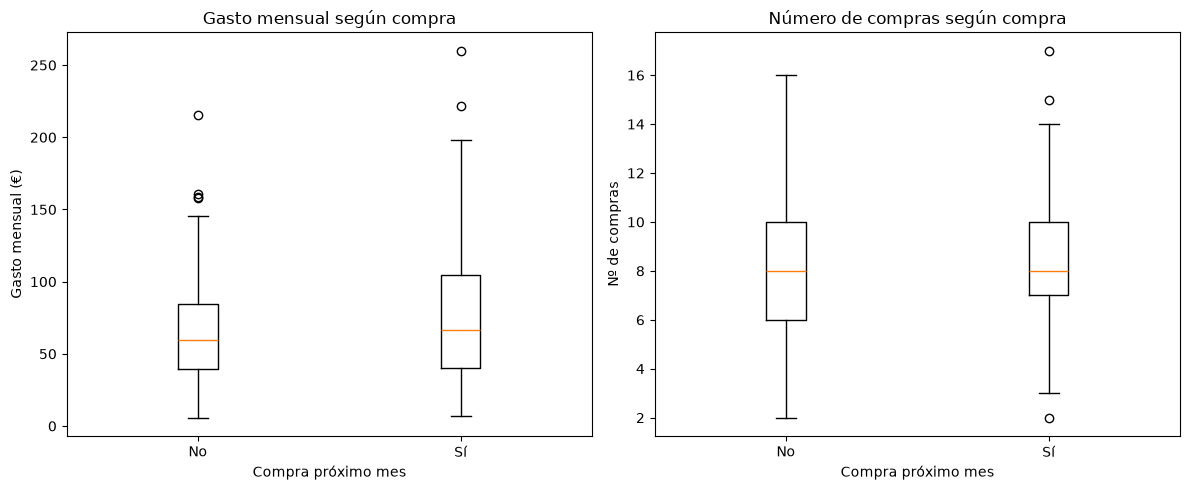

In [57]:
# TODO: primera visualización
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Boxplot de gasto mensual
no_gasto = df.loc[df["compra_proximo_mes"] == "No", "gasto_mensual"].dropna()
si_gasto = df.loc[df["compra_proximo_mes"] == "Sí", "gasto_mensual"].dropna()
axes[0].boxplot([no_gasto, si_gasto], tick_labels=["No", "Sí"])
axes[0].set_title("Gasto mensual según compra")
axes[0].set_xlabel("Compra próximo mes")
axes[0].set_ylabel("Gasto mensual (€)")

# Boxplot de número de compras
no_comp = df.loc[df["compra_proximo_mes"] == "No", "num_compras"].dropna()
si_comp = df.loc[df["compra_proximo_mes"] == "Sí", "num_compras"].dropna()
axes[1].boxplot([no_comp, si_comp], tick_labels=["No", "Sí"])
axes[1].set_title("Número de compras según compra")
axes[1].set_xlabel("Compra próximo mes")
axes[1].set_ylabel("Nº de compras")

plt.tight_layout()
plt.show()

In [59]:
# TODO: comparación categórica y tabla de proporciones
print("Nivel de fidelidad (%)")
prop_fidelidad = (pd.crosstab(df["nivel_fidelidad"], df["compra_proximo_mes"], normalize="index") * 100).round(2)
display(prop_fidelidad)

print("Dispositivo (%)")
prop_dispositivo = (pd.crosstab(df["dispositivo"], df["compra_proximo_mes"], normalize="index") * 100).round(2)
display(prop_dispositivo)

Nivel de fidelidad (%)


compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,69.14,30.86
Oro,62.65,37.35
Plata,60.00,40.00
Platino,38.00,62.00


Dispositivo (%)


compra_proximo_mes,No,Sí
dispositivo,,
Móvil,63.22,36.78
Ordenador,57.89,42.11
Tablet,64.00,36.00


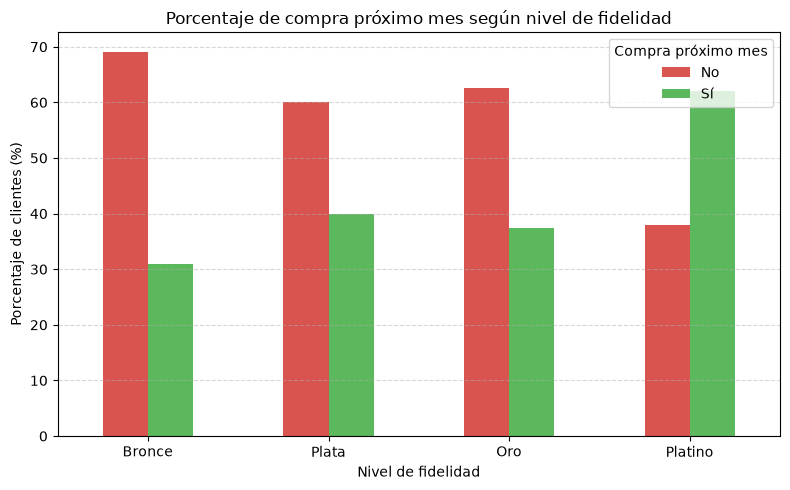

In [60]:
# TODO: segunda visualización
# TODO: segunda visualización
orden = ["Bronce", "Plata", "Oro", "Platino"]
prop_ordenada = prop_fidelidad.reindex(orden)

ax = prop_ordenada.plot(kind="bar", figsize=(8, 5), color=["#d9534f", "#5cb85c"])
plt.title("Porcentaje de compra próximo mes según nivel de fidelidad")
plt.xlabel("Nivel de fidelidad")
plt.ylabel("Porcentaje de clientes (%)")
plt.xticks(rotation=0)
plt.legend(title="Compra próximo mes")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Interpretación del reto

Resume qué características parecen diferenciar a ambos grupos.

Distingue entre:

- lo que **observas** en el dataset
- lo que **no puedes concluir** a partir de esos datos.

**Respuesta:**  

* **Lo que se observa en el dataset:** 
  * Existe una fuerte asociación con el nivel_fidelidad: mientras que en Bronce solo compra el 30,86 %, en Platino la proporción sube hasta el 62,00 %.
  * En las variables numéricas, el grupo que sí compra presenta un gasto_mensual mediano más elevado y mayor dispersión en sus importes, mientras que variables como ingresos_anuales apenas muestran diferencias entre ambos grupos.

* **Lo que no se puede concluir a partir de estos datos:** 
  * No se puede afirmar una relación de causalidad (por ejemplo, que subir artificialmente a un cliente a nivel Platino vaya a provocar que compre más, ya que influyen otros factores previos).
  * Tampoco se puede asegurar una separación perfecta entre grupos, dado que existe un claro solapamiento en el gasto mensual de quienes compran y quienes no, ni generalizar estos patrones fuera de esta muestra de 400 clientes sin un modelado posterior.


# Parte 19 - Informe final de EDA

## Ejercicio 19

Selecciona los **5 hallazgos más relevantes**.

Para cada uno indica:

- **Pregunta:** ¿qué queríamos averiguar?
- **Evidencia:** ¿qué estadística, tabla o gráfico lo respalda?
- **Interpretación:** ¿qué hemos observado?
- **Limitación:** ¿qué no podemos concluir?

#### Hallazgo 1
* **Pregunta:** ¿Cómo se distribuye la variable objetivo (compra_proximo_mes) en el conjunto de datos?
* **Evidencia:** Tabla de frecuencias y porcentajes de variables categóricas (value_counts / resumen categórico).
* **Interpretación:** El target presenta un ligero desbalanceo de clases, con un 61,50 % de clientes que no compran (246 muestras) frente a un 38,50 % que sí lo hacen (154 muestras).
* **Limitación:** Esta distribución refleja únicamente el comportamiento histórico de esta muestra de 400 clientes y no explica por sí sola los motivos de compra.

#### Hallazgo 2
* **Pregunta:** ¿Existen problemas de calidad, valores atípicos o datos faltantes que afecten al análisis?
* **Evidencia:** Tabla de estadística descriptiva (mínimos, máximos y conteo de nulos).
* **Interpretación:** Se detectó un valor erróneo evidente en edad (máximo de 195 años, cuando el siguiente valor es 75), 12 valores nulos repartidos entre antigüedad, ingresos (4) y gasto mensual (3), y 16 clientes con un valor mínimo exacto de 9.000,00 € en ingresos_anuales.
* **Limitación:** Sin consultar la fuente original de recolección de datos, no podemos saber si los 9.000 € son un tope real del sistema o un valor imputado por defecto, ni cuál era la edad real del registro erróneo.

#### Hallazgo 3
* **Pregunta:** ¿Influyen los ingresos anuales del cliente en su gasto mensual o existe una fuerte relación lineal entre las variables numéricas?
* **Evidencia:** Matriz de correlaciones de Pearson y diagrama de dispersión.
* **Interpretación:** No existe correlación lineal relevante entre ninguna pareja de variables numéricas; en concreto, ingresos_anuales y gasto_mensual tienen una correlación de -0.000367 (prácticamente cero).
* **Limitación:** El coeficiente de Pearson solo mide relaciones lineales, por lo que no descarta posibles relaciones no lineales o interacciones complejas al combinar varias variables.

#### Hallazgo 4
* **Pregunta:** ¿Se diferencian los clientes que compran de los que no compran según su gasto mensual?
* **Evidencia:** Comparación agrupada y diagrama de cajas de gasto_mensual frente a compra_proximo_mes.
* **Interpretación:** Quienes sí compran el mes siguiente muestran una mediana de gasto mensual superior y una mayor dispersión en sus importes (con valores que alcanzan los 260,00 €) respecto a quienes no compran.
* **Limitación:** Existe un amplio solapamiento entre las cajas de ambos grupos, por lo que el gasto mensual por sí solo no permite clasificar con total exactitud si un cliente comprará o no.

#### Hallazgo 5
* **Pregunta:** ¿Varía la proporción de compra del próximo mes según el nivel de fidelidad del cliente?
* **Evidencia:** Tabla de contingencia normalizada por filas y gráfico de barras de proporciones.
* **Interpretación:** Existe una clara asociación positiva: la tasa de compra aumenta progresivamente desde el 30,86 % en el nivel Bronce hasta el 62,00 % en el nivel Platino.
* **Limitación:** Esta asociación no implica causalidad; subir artificialmente a un cliente al nivel Platino no garantiza que vaya a comprar más, ya que intervienen factores previos como su hábito de compra o gasto histórico.

# Parte 20 - Conclusiones

## Ejercicio 20

Redacta unas conclusiones finales de entre **10 y 15 líneas**.

Incluye:

- características generales del dataset
- principales distribuciones
- posibles valores atípicos
- relaciones encontradas
- correlaciones relevantes
- diferencias entre grupos
- algún resultado que te haya sorprendido
- posibles problemas de calidad
- qué investigarías a continuación.

### Conclusiones

El dataset analizado consta de 400 clientes y 12 columnas, de las cuales 10 son variables predictoras, una es un identificador cliente_id y otra es la variable objetivo (compra_proximo_mes), configurando un problema de clasificación binaria ligeramente desbalanceado (61,50 % "No" frente a 38,50 % "Sí"). En cuanto a las distribuciones, num_compras muestra un comportamiento simétrico alrededor de una media de 8,23 compras, mientras que gasto_mensual presenta asimetría hacia la derecha (media de 69,09 € frente a mediana de 61,17 €) debido a valores atípicos superiores que alcanzan los 260,00 €.

Respecto a la calidad de los datos, destaca un error evidente en edad con un registro máximo de 195 años, además de 12 valores ausentes repartidos entre antigüedad, ingresos (4) y gasto (3), y 16 clientes con un valor mínimo exacto de 9.000,00 € en ingresos_anuales que sugiere un posible tope o relleno por defecto. Uno de los resultados más llamativos de la matriz de correlaciones es la ausencia total de relación lineal entre variables numéricas; de hecho, ingresos_anuales y gasto_mensual tienen una correlación prácticamente nula $-0.000367. 

Al comparar los grupos según el target, las mayores diferencias aparecen en el gasto_mensual (mayor mediana y dispersión en quienes compran) y, especialmente, en el nivel_fidelidad, donde la tasa de compra pasa del 30,86 % en Bronce al 62,00 % en Platino. Como siguientes pasos, investigaría posibles relaciones no lineales entre variables combinadas, imputaría los nulos, corregiría el registro erróneo de edad y codificaría las variables categóricas para entrenar modelos predictivos.

# Antes de entregar

Comprueba que:

- [ ] Has completado todos los ejercicios.
- [ ] Has respondido las preguntas en Markdown.
- [ ] Todos los gráficos tienen título.
- [ ] Los ejes están correctamente identificados.
- [ ] Has interpretado los resultados.
- [ ] Has diferenciado correlación de causalidad.
- [ ] No has eliminado automáticamente los outliers.
- [ ] Has ejecutado el notebook completo desde el principio sin errores.

**Nombre recomendado:** `Practica_05_Apellido_Nombre.ipynb`